# 채용공고 탐색적 데이터 분석 (EDA)
수집 → 전처리 → **분석·시각화** → RAG 구축 흐름의 분석 단계 (01_python ch11·ch12·ch13 방식)

- 입력 1 : `data/processed/postings.csv` - 통합 공고 표 60,100건 (build_postings.py 결과)
- 입력 2 : `data/chroma` 'postings' 컬렉션 - 추천에 실제로 쓰는 공고 521건 (recommend.py build 결과)
- 출력 : `data/eda/*.png` (발표 자료용 그림)

In [1]:
import collections
from pathlib import Path
import chromadb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc('font', family='Malgun Gothic')    # 윈도우즈 한글 (ch12)
plt.rc('axes', unicode_minus=False)       # 음수 부호 깨짐 방지
DATA_DIR = Path('..') / 'data'
FIG_DIR = DATA_DIR / 'eda'
FIG_DIR.mkdir(exist_ok=True)
BLUE, NAVY, LIGHT, GRAY, YELLOW = '#1F06AC', '#14123A', '#5882E8', '#9C98AE', '#E3EF4F'

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')

# 1. 데이터 불러오기

In [2]:
postings = pd.read_csv(DATA_DIR / 'processed' / 'postings.csv', dtype=str).fillna('')
print(postings.shape)
postings.head(2)

(60100, 14)


,doc_id,source,title,기업명,category,기업규모,시도,경력,마감일,url,기술태그,자격증태그,직무묶음,page_content
0,seoul_0,서울시,"산모.신생아 건강관리사, 육아도우미 모집",해와달케어,정보없음,중소·기타,서울,관계없음,2026-11-06,정보없음,회계프로그램,정보없음,범위밖,"채용제목: 산모.신생아 건강관리사, 육아도우미 모집\n모집직종: 육아 도우미(베이비..."
1,seoul_1,서울시,"산모.신생아 건강관리사, 육아도우미 모집",해와달케어,정보없음,중소·기타,서울,관계없음,2026-11-06,정보없음,회계프로그램,정보없음,범위밖,"채용제목: 산모.신생아 건강관리사, 육아도우미 모집\n모집직종: 육아 도우미(베이비..."


In [3]:
postings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60100 entries, 0 to 60099
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   doc_id        60100 non-null  object
 1   source        60100 non-null  object
 2   title         60100 non-null  object
 3   기업명           60100 non-null  object
 4   category      60100 non-null  object
 5   기업규모          60100 non-null  object
 6   시도            60100 non-null  object
 7   경력            60100 non-null  object
 8   마감일           60100 non-null  object
 9   url           60100 non-null  object
 10  기술태그          60100 non-null  object
 11  자격증태그         60100 non-null  object
 12  직무묶음          60100 non-null  object
 13  page_content  60100 non-null  object
dtypes: object(14)
memory usage: 6.4+ MB


In [4]:
# 결측치 확인 : 전처리에서 빈 값은 '정보없음'으로 채웠으므로 '정보없음' 개수를 같이 봄 (ch13)
pd.DataFrame({'빈 값': (postings == '').sum(), '정보없음': (postings == '정보없음').sum()}).T

,doc_id,source,title,기업명,category,기업규모,시도,경력,마감일,url,기술태그,자격증태그,직무묶음,page_content
빈 값,0,0,0,0,0,0,0,0,194,0,0,0,0,0
정보없음,0,0,0,0,27394,367,19736,19760,0,39501,53705,53067,0,0


In [5]:
# 추천에 쓰는 벡터DB (직무묶음이 있는 공고만 저장됨)
client = chromadb.PersistentClient(path=str(DATA_DIR / 'chroma'))
got = client.get_collection('postings').get(include=['metadatas', 'documents'])
vdb = pd.DataFrame(got['metadatas'])
vdb['임베딩글'] = got['documents']
print(vdb.shape)
vdb[['title', '기업명', '기업규모', '경력', '직무묶음', '기술태그']].head(3)

(528, 12)


,title,기업명,기업규모,경력,직무묶음,기술태그
0,"일반임기제공무원(인공지능 및 빅데이터 업무담당, 연봉등급 5호) 경력경쟁채용시험 시...",대법원 법원행정처,공공기관,정보없음,데이터 분석·사이언스,인공지능;빅데이터
1,"일반임기제공무원(인공지능 및 빅데이터 업무담당, 연봉등급 6호) 경력경쟁채용시험 시...",대법원 법원행정처,공공기관,정보없음,데이터 분석·사이언스,인공지능;빅데이터
2,2025년 제주대학교 국립대학육성사업 IR센터 데이터분석가 채용 공고,제주대학교 기획처,공공기관,정보없음,데이터 분석·사이언스,정보없음


# 2. 출처별 공고 수

source
서울시     39501
나라일터    19530
ALIO      527
인크루트      482
잡다         60
Name: count, dtype: int64


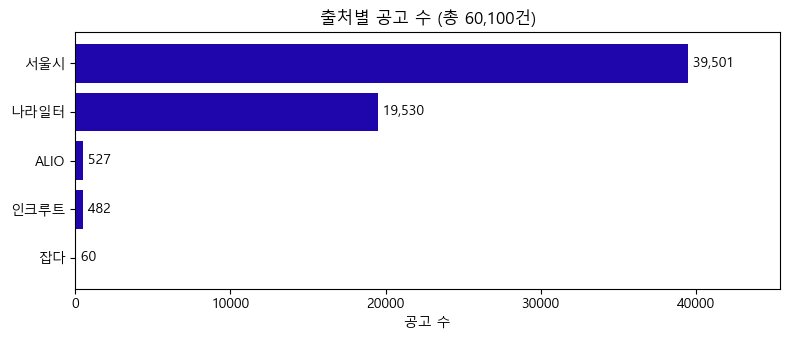

In [6]:
src = postings['source'].value_counts()
print(src)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(src.index[::-1], src.values[::-1], color=BLUE)
for i, v in enumerate(src.values[::-1]):
    ax.text(v, i, f' {v:,}', va='center')
ax.set_title(f'출처별 공고 수 (총 {len(postings):,}건)')
ax.set_xlabel('공고 수')
ax.set_xlim(0, src.max() * 1.15)
save(fig, '01_source.png')

> 서울시 일자리포털 API와 나라일터가 98% 이상이다. 민간 크롤링(인크루트·잡다)은 상세 요건이 풍부하지만 수가 적다.

# 3. 경력 조건 분포 → 신입 필터가 필요한 이유

경력
관계없음    45.1
정보없음    32.9
경력      16.3
신입       5.7
Name: count, dtype: float64


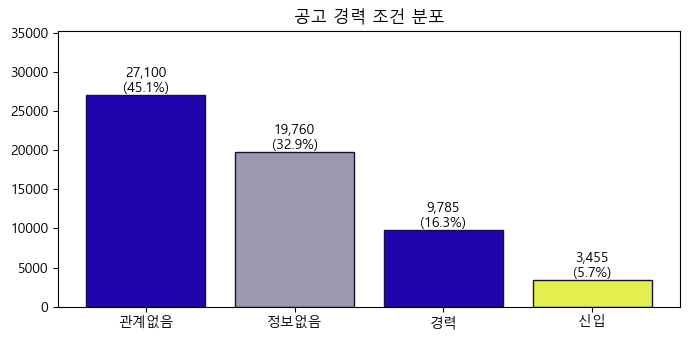

In [7]:
career = postings['경력'].value_counts()
print((career / len(postings) * 100).round(1))
fig, ax = plt.subplots(figsize=(7, 3.5))
colors = [YELLOW if k == '신입' else (GRAY if k == '정보없음' else BLUE) for k in career.index]
ax.bar(career.index, career.values, color=colors, edgecolor=NAVY)
for i, v in enumerate(career.values):
    ax.text(i, v, f'{v:,}\n({v / len(postings):.1%})', ha='center', va='bottom')
ax.set_title('공고 경력 조건 분포')
ax.set_ylim(0, career.max() * 1.3)
save(fig, '02_career.png')

> '신입'을 명시한 공고는 소수이고 '경력' 공고도 많다. 신입 지원자에게 경력 공고가 섞이지 않도록 검색 단계의 '신입 가능만' 필터를 만들었다 (recommend.py newbie_only).

# 4. 기업규모 분포

기업규모
중소·기타     62.2
공공기관      33.4
중견(근사)     2.7
대기업집단      0.9
정보없음       0.6
외국계        0.2
Name: count, dtype: float64


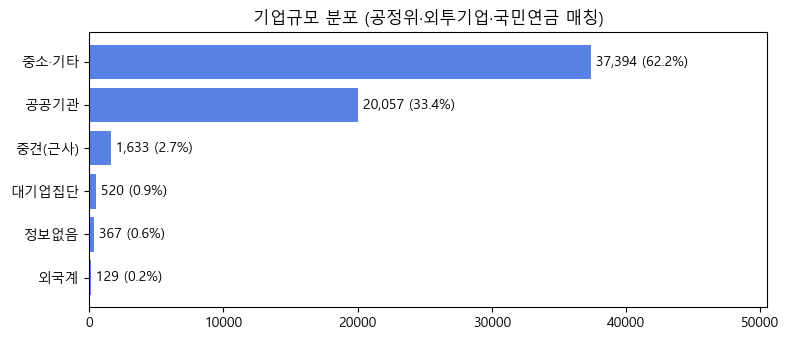

In [8]:
size = postings['기업규모'].value_counts()
print((size / len(postings) * 100).round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(size.index[::-1], size.values[::-1], color=LIGHT)
for i, v in enumerate(size.values[::-1]):
    ax.text(v, i, f' {v:,} ({v / len(postings):.1%})', va='center')
ax.set_title('기업규모 분포 (공정위·외투기업·국민연금 매칭)')
ax.set_xlim(0, size.max() * 1.35)
save(fig, '03_company_size.png')

> 공고에는 기업규모가 없어 공정위 대기업집단, 외국인투자기업, 국민연금 가입자수로 직접 판별했다 (match_company_size.py). 대기업집단·외국계 공고는 1%가 안 된다.

# 5. 지역 분포

시도
경기      24224
정보없음    19736
서울      10477
인천       5174
경남         88
부산         48
대전         44
세종         40
Name: count, dtype: int64


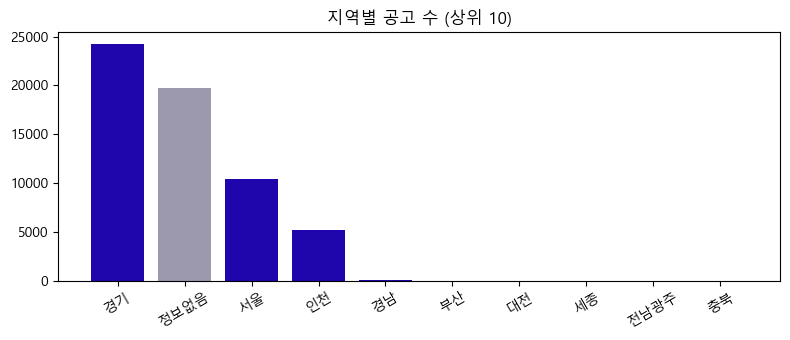

In [9]:
# 시도 표기 확인 ('경기도'는 build_postings.py 에서 '경기'로 통일됨)
print(postings['시도'].value_counts().head(8))
sido = postings['시도']
top = sido.value_counts().head(10)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(top.index, top.values, color=[GRAY if k == '정보없음' else BLUE for k in top.index])
ax.set_title('지역별 공고 수 (상위 10)')
plt.setp(ax.get_xticklabels(), rotation=30)
save(fig, '04_region.png')

> 수도권(경기·서울·인천)에 몰려 있다. 지역이 없는 공고(정보없음)도 많아 지역은 추천 조건으로 쓰지 않았다. 원본에 '경기'와 '경기도'가 섞여 있던 것은 build_postings.py 에서 '경기'로 통일했다.

# 6. 직무묶음별 공고 수 (벡터DB)

직무묶음 수 : 15


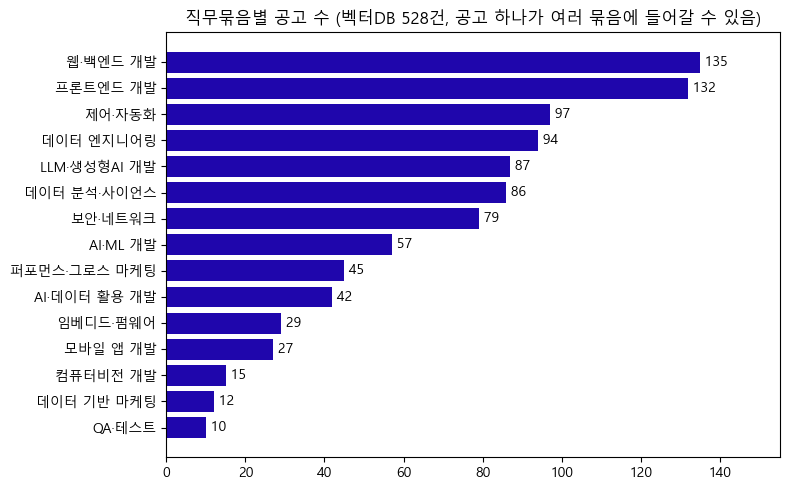

In [10]:
groups = vdb['직무묶음'].str.split(';').explode()
groups = groups[~groups.isin(['', '정보없음', '범위밖'])].value_counts()
print('직무묶음 수 :', len(groups))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(groups.index[::-1], groups.values[::-1], color=BLUE)
for i, v in enumerate(groups.values[::-1]):
    ax.text(v, i, f' {v}', va='center')
ax.set_title(f'직무묶음별 공고 수 (벡터DB {len(vdb)}건, 공고 하나가 여러 묶음에 들어갈 수 있음)')
ax.set_xlim(0, groups.max() * 1.15)
save(fig, '05_job_group.png')

# 7. 직무묶음별 요구 기술 (히트맵)

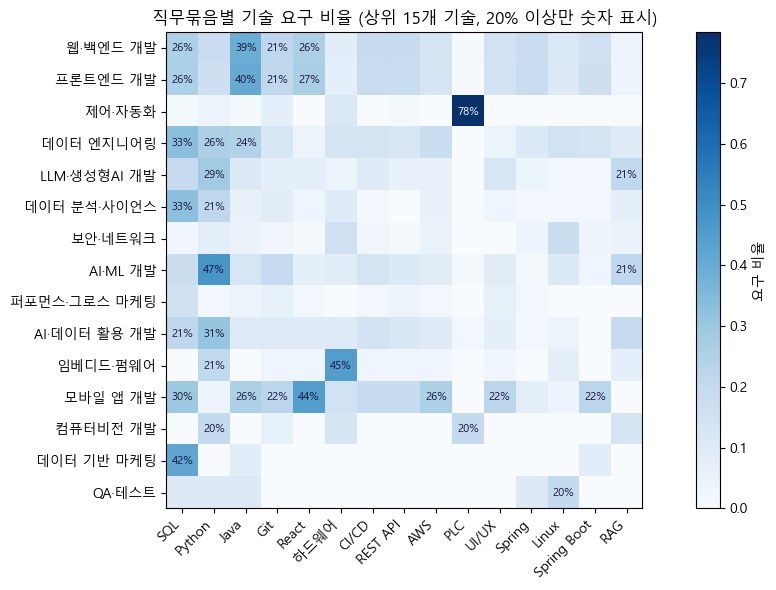

In [11]:
# 너무 넓은 태그와 문서 도구는 빼고 봄 (웹 직무 알아보기 화면과 같은 기준)
GENERIC = {'웹', '앱', '인공지능', '데이터베이스', '소프트웨어', 'API', '백엔드', '프론트엔드', '빅데이터', '정보없음', '', 'Word', 'Excel', 'PowerPoint', '한글', 'MS Office'}
rows = []
for _, r in vdb.iterrows():
    for g in r['직무묶음'].split(';'):
        for t in set(r['기술태그'].split(';')) - GENERIC:
            rows.append((g, t))
gt = pd.DataFrame(rows, columns=['직무묶음', '기술'])
table = pd.crosstab(gt['직무묶음'], gt['기술'])
top_tech = table.sum().sort_values(ascending=False).head(15).index
order = [g for g in groups.index if g in table.index]
ratio = table.loc[order, top_tech].div(groups[order], axis=0)   # 그 직무 공고 중 해당 기술을 요구하는 비율
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(ratio.values, cmap='Blues', vmin=0, vmax=ratio.values.max())
ax.set_xticks(range(len(top_tech)), top_tech, rotation=45, ha='right')
ax.set_yticks(range(len(order)), order)
for i in range(ratio.shape[0]):
    for j in range(ratio.shape[1]):
        v = ratio.iat[i, j]
        if v >= 0.2:
            ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if v > 0.5 else NAVY)
fig.colorbar(im, ax=ax, label='요구 비율')
ax.set_title('직무묶음별 기술 요구 비율 (상위 15개 기술, 20% 이상만 숫자 표시)')
save(fig, '06_tech_heatmap.png')

> 직무마다 요구 기술이 뚜렷하게 다르다. 이 비율이 로드맵의 '요구 비율' 우선순위 기준이다 (roadmap.py).

# 8. 임베딩할 본문 길이 → 청킹을 하지 않은 이유

count      528.0
mean       847.0
std        892.0
min         16.0
25%        338.0
50%        655.0
75%       1141.0
max      11866.0
Name: 임베딩글, dtype: float64


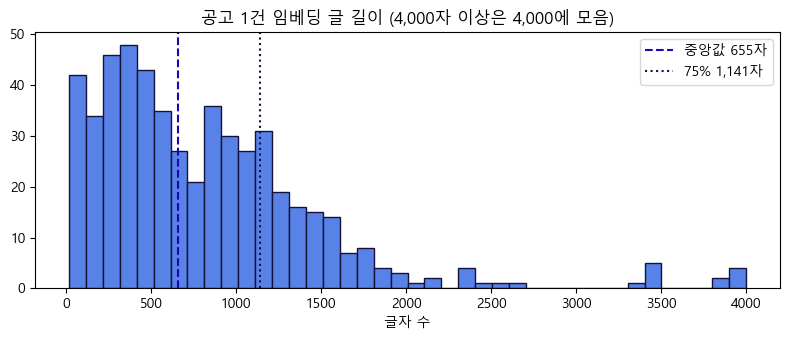

In [12]:
length = vdb['임베딩글'].str.len()
print(length.describe().round(0))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(length.clip(upper=4000), bins=40, color=LIGHT, edgecolor=NAVY)
ax.axvline(length.median(), color=BLUE, linestyle='--', label=f'중앙값 {length.median():,.0f}자')
ax.axvline(length.quantile(0.75), color=NAVY, linestyle=':', label=f'75% {length.quantile(0.75):,.0f}자')
ax.set_title('공고 1건 임베딩 글 길이 (4,000자 이상은 4,000에 모음)')
ax.set_xlabel('글자 수')
ax.legend()
save(fig, '07_text_length.png')

> 대부분 공고가 짧아 임베딩 모델 입력 한도(8,191토큰) 안에 들어간다. 추천 단위가 공고 한 건이므로 수업의 RecursiveCharacterTextSplitter 청킹 대신 공고 1건 = Document 1개로 저장했다.

# 9. 정리
- 신입 명시 공고가 적고 경력 공고가 많음 → 신입 필터
- 기업규모는 공고에 없음 → 외부 데이터로 판별, 대기업·외국계는 1% 미만
- 직무마다 요구 기술이 다름 → 기술 충족률 재순위 + 요구 비율 로드맵
- 공고 길이가 짧음 → 청킹 없이 공고 1건 = 문서 1개